# CS2 - Carbonate Reservoir Characterization & Rock Typing

**Case Study - Petrophys Curriculum**

Well **HW-10** (Costa field, carbonate, depths in **feet**) + core data

---

## 1. The brief

> *"We have logged and cored a carbonate reservoir interval in well HW-10. Reservoir
> engineering needs a **rock-type profile** and a **reservoir-quality assessment**: where
> are the best flow units, how do porosity and permeability relate, is the interval
> hydrocarbon-bearing, and where should we complete? Calibrate everything to the core so the
> answer is defensible."*

**Who is asking:** the asset team's reservoir engineer, ahead of a completion decision.

**Why it matters.** Carbonates are notoriously heterogeneous: pore geometry (moldic, vuggy,
intercrystalline) decouples porosity from permeability, so a single porosity-permeability
line is meaningless. We must **partition** the rock into flow units (hydraulic flow units /
rock types) using the Amaefule Reservoir Quality Index (RQI) / Flow Zone Indicator (FZI)
framework, calibrate the log petrophysics to the core plugs, and then rank the reservoir.

**The deliverable (produced by the end of this notebook):**
1. A **rock-type / flow-unit track** vs depth.
2. A **poro-perm cloud** coloured by rock type with fitted transform lines.
3. **Core-vs-log calibration** crossplots (porosity and permeability).
4. A **saturation-height** curve from a fitted Leverett J-function.
5. A **reservoir-quality summary figure + table** and the best intervals to complete.

This case study *chains* many modules; it references the single-module tutorials rather than
re-teaching them.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

import petrophys
from petrophys.io import read_las

# Physics / interpretation modules (all verified against source)
from petrophys.petrophysics import porosity as poro
from petrophys.petrophysics import saturation as sat
from petrophys.petrophysics import saturation_height as sath
from petrophys.environmental.temperature import calculate_temperature_profile, arps_equation
from petrophys import core as core_mod
from petrophys import reservoir as res_mod

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)
print('petrophys', petrophys.__version__)
print('Costa wells available:', petrophys.list_samples('costa'))

petrophys 0.1.0
Costa wells available: ['HW-10', 'HW-24', 'HW-25', 'HW-26', 'HW-27', 'HW-28', 'HW-29', 'HW-3', 'HW-30', 'HW-31', 'HW-32', 'HW-4', 'HW-5', 'HW-6', 'HW-7', 'HW-8', 'HW-9']


## 2. The well & the data

HW-10 is one of 17 wells in the bundled **Costa** carbonate field. Let's inventory exactly
what we have - measured logs *and* core - before planning the workflow.

In [2]:
well = read_las(petrophys.sample('HW-10'))

print('Well            :', well.name)
print('Depth unit      :', well.depth_unit)
print('Interval        : %.1f - %.1f %s' % (well.start_depth, well.stop_depth, well.depth_unit))
print('Samples / step  : %d @ %.2f %s' % (well.n_samples, well.step, well.depth_unit))
print()
print('%-10s %-9s %6s %6s %10s %10s' % ('CURVE','UNIT','VALID','NULL','MIN','MAX'))
print('-'*56)
for m in well.curves:
    c = well.get(m)
    lo = np.nanmin(c.data) if c.valid_count() else float('nan')
    hi = np.nanmax(c.data) if c.valid_count() else float('nan')
    print('%-10s %-9s %6d %6d %10.3g %10.3g' %
          (m, c.unit or '-', c.valid_count(), c.null_count(), lo, hi))

Well            : HW-10
Depth unit      : ft
Interval        : 8440.0 - 8630.0 ft
Samples / step  : 381 @ 0.50 ft

CURVE      UNIT       VALID   NULL        MIN        MAX
--------------------------------------------------------
GR         gAPI         381      0       5.37       33.9
RHOB       g/cm3        381      0       2.25       2.75
NPHI       ft3/ft3      381      0       0.02       0.27
DT         us/ft          0    381        nan        nan
PHIE_CC    ft3/ft3      381      0          0       0.27
RT         ohm.m        381      0       0.22       38.2
SW_INPUT   v/v          160    221       0.38          1
PERM_CC    mD           311     70       0.04        345


**Reading the inventory.**

*Wireline logs:* `GR`, `RHOB`, `NPHI`, `RT` are complete. `DT` (sonic) is **all-null** - no
acoustic porosity available here.

*Core data* (the reason this well was chosen):
- `PHIE_CC` - core plug porosity (v/v)
- `PERM_CC` - core plug permeability (mD), covers a huge range (~0.04 to ~345 mD)
- `SW_INPUT` - core / SCAL water saturation (v/v), present only over the cored transition zone

The **very low GR** (~5-34 gAPI) is the fingerprint of a *clean carbonate*: negligible clay.
That immediately shapes our model choices (Section 3).

In [3]:
# Load header Archie parameters LIVE - these ship with the LAS and must not be invented.
RW  = well.get_parameter('RW')    # water resistivity at RWT
A   = well.get_parameter('A')     # tortuosity
M   = well.get_parameter('M')     # cementation exponent
N   = well.get_parameter('N')     # saturation exponent
BHT = well.get_parameter('BHT')   # bottom-hole temperature (deg F)
RWT = well.get_parameter('RWT')   # temperature at which RW is quoted (deg F)

print('Archie / petrophysical header parameters (read from the LAS):')
print('  RW  = %.4f ohm.m  (quoted at RWT = %.0f deg F)' % (RW, RWT))
print('  A   = %.3f' % A)
print('  M   = %.3f  (cementation exponent)' % M)
print('  N   = %.3f  (saturation exponent)' % N)
print('  BHT = %.0f deg F  (bottom-hole temperature)' % BHT)

Archie / petrophysical header parameters (read from the LAS):
  RW  = 0.1373 ohm.m  (quoted at RWT = 68 deg F)
  A   = 1.000
  M   = 2.030  (cementation exponent)
  N   = 2.000  (saturation exponent)
  BHT = 251 deg F  (bottom-hole temperature)


## 3. Workflow plan (and why in this order)

| # | Step | Module | Why here |
|---|------|--------|----------|
| 1 | Porosity from RHOB/NPHI (limestone matrix) | `petrophysics.porosity` | An **independent** log porosity to calibrate against core |
| 2 | Temperature-correct RW, then Archie Sw | `environmental.temperature`, `petrophysics.saturation` | Clean carbonate -> Archie is valid; RW must be at formation T |
| 3 | Core-log calibration (porosity + poro-perm transform) | `core` | Tie the logs to ground truth; expose poro-perm scatter |
| 4 | RQI / FZI flow units -> rock types | `reservoir` | Partition the heterogeneous carbonate into hydraulic flow units |
| 5 | Saturation-height (fit Leverett J on core) | `petrophysics.saturation_height` | Physically-based Sw model; cross-check vs log Sw |
| 6 | Net pay with carbonate cutoffs | `reservoir.net_pay` | Turn interpretation into a completion recommendation |

**Why Archie (and not a shaly-sand model)?** Archie's law assumes the rock matrix is a perfect
insulator and all conductivity comes from brine in the pores:

$$S_w^{\,n} = \frac{a\,R_w}{\phi^{m}\,R_t}$$

That assumption holds for a **clean** carbonate (very low GR, negligible clay-bound water).
If GR were high, or if independent evidence showed dispersed clay / conductive minerals, we
would switch to **Waxman-Smits** or **Dual-Water**, which add a clay-conductivity term (CEC /
bound-water). We keep those in reserve and justify the Archie choice from the data.

> Note the header **M = 2.03** - slightly above the classic 2.0 - which is typical for
> carbonates where cementation reduces pore connectivity.

## 4. Execution

### 4.1 Independent log porosity (limestone matrix)

For a clean limestone we take the matrix density as **2.71 g/cc** (calcite) and fresh-fluid
density 1.0 g/cc for the density porosity, then combine density + neutron. This gives a log
porosity that is *independent* of the core `PHIE_CC` - essential, because calibrating
`PHIE_CC` against itself would be trivially perfect and tell us nothing.

In [4]:
rhob = well.get('RHOB').data
nphi = well.get('NPHI').data

RHOB_MATRIX = 2.71   # calcite / limestone
RHOB_FLUID  = 1.00   # fresh mud filtrate

phid = poro.density_porosity(rhob, rhob_matrix=RHOB_MATRIX, rhob_fluid=RHOB_FLUID)
phit = poro.total_porosity(nphi, phid, method='adaptive')   # combine N & D
phit = np.clip(phit, 0.0, 0.45)

well.add_curve('PHIT_LOG', phit, unit='v/v', description='Log total porosity (N-D, limestone)')

print('Log porosity (N-D, limestone matrix):')
print('  mean = %.3f  p10 = %.3f  p50 = %.3f  p90 = %.3f' %
      (np.nanmean(phit), np.nanpercentile(phit,10),
       np.nanpercentile(phit,50), np.nanpercentile(phit,90)))
print('Core PHIE_CC for reference:')
cc = well.get('PHIE_CC').data
print('  mean = %.3f  p10 = %.3f  p50 = %.3f  p90 = %.3f' %
      (np.nanmean(cc), np.nanpercentile(cc,10),
       np.nanpercentile(cc,50), np.nanpercentile(cc,90)))

Log porosity (N-D, limestone matrix):
  mean = 0.182  p10 = 0.016  p50 = 0.225  p90 = 0.255
Core PHIE_CC for reference:
  mean = 0.182  p10 = 0.000  p50 = 0.230  p90 = 0.260


### 4.2 Water saturation - the RW temperature correction that makes Archie work

The header quotes `RW = %s ohm.m` **at RWT = 68 deg F** (a lab / surface temperature). Down
at reservoir conditions (BHT ~ 251 deg F) brine is far more conductive, so its resistivity is
much lower. Using the surface RW directly makes $R_o = a R_w / \phi^m$ far too large, Archie
returns $S_w > 1$ everywhere, and the answer is garbage.

The fix is the classic **Arps** temperature correction of RW from RWT to the formation
temperature at each depth, using a temperature profile built from the BHT.

In [5]:
# Build a temperature profile from surface (68 F) to BHT.
tprof = calculate_temperature_profile(well, bht=BHT, surface_temp=RWT)
tf = tprof.temperature   # deg F at each depth
print('Formation temperature over reservoir: %.0f - %.0f deg F (mean %.0f)'
      % (np.nanmin(tf), np.nanmax(tf), np.nanmean(tf)))

# Arps-correct RW from RWT (68 F) to formation temperature at each depth.
rw_fm = arps_equation(RW, RWT, tf)
print('RW at surface  (RWT=%.0f F) : %.4f ohm.m' % (RWT, RW))
print('RW at formation T (mean)   : %.4f ohm.m  <- much lower, as expected' % np.nanmean(rw_fm))

Formation temperature over reservoir: 241 - 245 deg F (mean 243)
RW at surface  (RWT=68 F) : 0.1373 ohm.m
RW at formation T (mean)   : 0.0411 ohm.m  <- much lower, as expected


In [6]:
rt = well.get('RT').data

# Archie with formation-temperature RW and the REAL header m, n, a.
sw_raw = sat.archie(rt, rw_fm, phit, a=A, m=M, n=N)
sw = np.clip(sw_raw, 0.0, 1.0)
well.add_curve('SW_ARCHIE', sw, unit='v/v', description='Archie Sw (RW @ formation T)')

# Compare against core SW_INPUT where available.
core_sw = well.get('SW_INPUT').data
m_cmp = np.isfinite(core_sw) & np.isfinite(sw)
r = np.corrcoef(sw[m_cmp], core_sw[m_cmp])[0, 1]
print('Archie Sw vs core SW_INPUT:')
print('  n overlap points = %d' % m_cmp.sum())
print('  correlation r    = %.3f' % r)
print('  mean log Sw      = %.3f' % np.nanmean(sw[m_cmp]))
print('  mean core Sw     = %.3f' % np.nanmean(core_sw[m_cmp]))

Archie Sw vs core SW_INPUT:
  n overlap points = 160
  correlation r    = 0.972
  mean log Sw      = 0.791
  mean core Sw     = 0.669


The temperature-corrected Archie Sw now **tracks the core saturation (r ~ 0.97)**, which
validates both the Archie choice and the RW correction. The log slightly over-reads relative
to core (a common bias: log Sw sees clay-bound / micro-porosity water, and RT is a bulk
measurement), which we carry forward as a known caveat.

### 4.3 Core-log calibration

We wrap the core plugs in a `CoreData` object and do two calibrations:
1. **Porosity:** log `PHIT_LOG` vs core `PHIE_CC` -> bias / RMSE / regression.
2. **Poro-perm transform:** fit $\log_{10}(K) = A\,\phi + B$ on the core plugs.

The poro-perm transform will show the *scatter* that motivates rock typing.

In [7]:
depth = well.depth
core = core_mod.CoreData(
    depth=depth,
    porosity=well.get('PHIE_CC').data,
    permeability=well.get('PERM_CC').data,
    sw=well.get('SW_INPUT').data,
)

# (a) Porosity calibration: independent LOG porosity vs CORE porosity.
cal = core_mod.calibrate_porosity(well, core, log_curve='PHIT_LOG')
print('POROSITY calibration  (log PHIT_LOG  vs  core PHIE_CC)')
print('  n points  = %d' % cal.n_points)
print('  R^2       = %.3f' % cal.r_squared)
print('  bias      = %+.4f v/v   (log minus core)' % cal.bias)
print('  RMSE      = %.4f v/v' % cal.rmse)
print('  slope     = %.3f   intercept = %+.4f' % (cal.slope, cal.intercept))
print()

# (b) Poro-perm transform on the core plugs.
ppt = core_mod.fit_poro_perm_transform(core, min_perm=0.01)
print('PORO-PERM transform   log10(K) = A*phi + B')
print('  A = %.3f   B = %.3f' % (ppt.A, ppt.B))
print('  R^2 = %.3f   n = %d   RMSE(log10K) = %.3f'
      % (ppt.r_squared, ppt.n_points, ppt.rmse))
print('  -> predicted K at phi=0.20 : %.1f mD' % ppt.predict(0.20))

POROSITY calibration  (log PHIT_LOG  vs  core PHIE_CC)
  n points  = 320
  R^2       = 0.995
  bias      = -0.0032 v/v   (log minus core)
  RMSE      = 0.0049 v/v
  slope     = 0.995   intercept = -0.0020

PORO-PERM transform   log10(K) = A*phi + B
  A = 7.139   B = -1.079
  R^2 = 0.261   n = 310   RMSE(log10K) = 0.593
  -> predicted K at phi=0.20 : 2.2 mD


**Two very different R^2 values - and that is the whole point.**

- Porosity calibration R^2 ~ **0.99**: the log porosity and core porosity agree almost
  perfectly. Our petrophysics is sound.
- Single poro-perm transform R^2 ~ **0.26**: a *single* line explains only a quarter of the
  permeability variance. In a carbonate, porosity alone does **not** predict permeability -
  pore geometry does. **This is exactly why we need rock typing (Section 4.4).**

### 4.4 Rock typing - RQI / FZI hydraulic flow units

The Amaefule *et al.* (1993) framework separates the pore-geometry effect from porosity:

$$RQI = 0.0314\sqrt{K/\phi} \quad\text{(um)}, \qquad
\phi_z = \frac{\phi}{1-\phi}, \qquad
FZI = \frac{RQI}{\phi_z}$$

Rock with a **constant FZI** falls on a single straight line in $\log RQI$ vs $\log\phi_z$
space and behaves as one hydraulic flow unit. We cluster the core plugs into flow units with
`calculate_flow_units`.

> **API note (verified from source):** `calculate_flow_units(perm, phi, ...)` takes
> **permeability FIRST**, then porosity - the opposite of RQI's visual order. Getting this
> backwards silently produces nonsense.

In [8]:
perm_cc = well.get('PERM_CC').data
phie_cc = well.get('PHIE_CC').data

good = np.isfinite(perm_cc) & np.isfinite(phie_cc) & (perm_cc > 0) & (phie_cc > 0)
K_c   = perm_cc[good]
PHI_c = phie_cc[good]
D_c   = depth[good]

# NOTE the argument order: permeability FIRST, porosity SECOND.
fu = res_mod.calculate_flow_units(K_c, PHI_c, method='kmeans', max_units=4)

print('Flow-unit clustering (core plugs):')
print('  n plugs        = %d' % good.sum())
print('  n flow units   = %d' % fu.n_units)
print('  FZI unit means = %s' % np.array2string(fu.fzi_unit_mean, precision=3))
print('  FZI boundaries = %s' % np.array2string(fu.fzi_boundaries, precision=3))
print('  plug counts    = %s' % fu.counts)

Flow-unit clustering (core plugs):
  n plugs        = 310
  n flow units   = 3
  FZI unit means = [0.286 0.581 1.795]
  FZI boundaries = [0.408 1.021]
  plug counts    = [190  77  43]


In [9]:
# Order rock types by ascending FZI so RRT1=poorest ... RRTn=best.
order = np.argsort(fu.fzi_unit_mean)
rank_of_unit = {int(u+1): int(np.where(order == u)[0][0] + 1) for u in range(fu.n_units)}
rrt = np.array([rank_of_unit[int(h)] for h in fu.hfu])   # 1..n_units, higher = better

rows = []
for rt_id in range(1, fu.n_units + 1):
    sel = rrt == rt_id
    rows.append({
        'RockType': 'RRT%d' % rt_id,
        'N_plugs' : int(sel.sum()),
        'Phi_mean': round(float(PHI_c[sel].mean()), 3),
        'K_median_mD': round(float(np.median(K_c[sel])), 2),
        'K_max_mD': round(float(K_c[sel].max()), 1),
        'RQI_mean': round(float(fu.rqi[sel].mean()), 3),
        'FZI_mean': round(float(fu.fzi[sel].mean()), 3),
        'Depth_top': round(float(D_c[sel].min()), 1),
        'Depth_base': round(float(D_c[sel].max()), 1),
    })
rt_table = pd.DataFrame(rows)
print('Per-rock-type statistics (RRT1 = poorest, RRT%d = best):' % fu.n_units)
print(rt_table.to_string(index=False))

best_rt = fu.n_units
best_sel = rrt == best_rt
print()
print('Best rock type = RRT%d : median K = %.1f mD, mean phi = %.3f'
      % (best_rt, np.median(K_c[best_sel]), PHI_c[best_sel].mean()))

Per-rock-type statistics (RRT1 = poorest, RRT3 = best):
RockType  N_plugs  Phi_mean  K_median_mD  K_max_mD  RQI_mean  FZI_mean  Depth_top  Depth_base
    RRT1      190     0.227         2.20       5.8     0.089     0.293     8462.5      8613.5
    RRT2       77     0.207         5.67      25.7     0.159     0.599     8463.5      8614.5
    RRT3       43     0.205        42.40     345.3     0.494     1.986     8460.5      8615.0

Best rock type = RRT3 : median K = 42.4 mD, mean phi = 0.205


### 4.5 Saturation-height model (Leverett J-function)

A saturation-height function predicts Sw from *height above the free-water level (FWL)* and
rock quality - independent of resistivity. We fit a Leverett **J-function** on the core, which
normalises capillary pressure for permeability and porosity:

$$J = 0.21645\,\frac{P_c}{\sigma\cos\theta}\sqrt{K/\phi}, \qquad S_w = a\,J^{\,b}$$

We have core Sw, K and phi but no direct lab $P_c$, so we reconstruct $P_c$ from **height
above a FWL** (buoyancy: $P_c = 0.433(\rho_w-\rho_{hc})\,h$). Core Sw approaches ~1 near the
base of the cored interval, so we place the FWL just below it.

In [10]:
FWL = 8540.0    # ft - just below the deepest core Sw point (Sw -> ~1 there)
SG_WATER, SG_HC = 1.00, 0.80
IFT, THETA = 30.0, 30.0   # oil-brine

sw_c   = well.get('SW_INPUT').data
mJ = (np.isfinite(sw_c) & np.isfinite(perm_cc) & np.isfinite(phie_cc)
      & (perm_cc > 0) & (phie_cc > 0) & (sw_c < 1.0))

height = FWL - depth[mJ]                                   # ft above FWL
pc     = sath.pc_from_height(height, sg_water=SG_WATER, sg_hc=SG_HC)
Jvals  = sath.leverett_j(pc, perm_cc[mJ], phie_cc[mJ], ift=IFT, theta=THETA)

okJ = np.isfinite(Jvals) & (Jvals > 0)
jmodel = sath.fit_j_function(Jvals[okJ], sw_c[mJ][okJ], form='power',
                             ift=IFT, theta=THETA, sg_hc=SG_HC)
print('Fitted J-function  Sw = a * J^b')
print('  a   = %.4f' % jmodel.a)
print('  b   = %.4f' % jmodel.b)
print('  R^2 = %.3f' % jmodel.r2)

Fitted J-function  Sw = a * J^b
  a   = 0.4822
  b   = -0.1437
  R^2 = 0.572


In [11]:
# Predict Sw vs depth from the J-model + FWL, using log/core K and phi.
sw_jh = sath.saturation_height_from_logs(well, jmodel, fwl_depth=FWL)
well.add_curve('SW_JHEIGHT', sw_jh, unit='v/v', description='Sw from J-function height model')

mcmp = np.isfinite(sw_jh) & np.isfinite(core_sw)
print('Saturation-height Sw vs core SW_INPUT:')
print('  n overlap = %d' % mcmp.sum())
print('  corr r    = %.3f' % np.corrcoef(sw_jh[mcmp], core_sw[mcmp])[0,1])
print('  mean J-height Sw = %.3f   mean core Sw = %.3f'
      % (np.nanmean(sw_jh[mcmp]), np.nanmean(core_sw[mcmp])))

Saturation-height Sw vs core SW_INPUT:
  n overlap = 151
  corr r    = 0.751
  mean J-height Sw = 0.654   mean core Sw = 0.667


### 4.6 Net pay with carbonate-appropriate cutoffs

Carbonate cutoffs differ from clastics: clay is negligible (so the Vcl cutoff is loose), but
because low-FZI micro-porosity holds immovable water, we apply a **porosity cutoff** and a
**Sw cutoff** to isolate movable-hydrocarbon rock. We pass `lithology='carbonate'` and set the
Sw curve to our temperature-corrected Archie result.

In [12]:
# calculate_net_pay reads VCL, PHIE, SW curves off the well.
gr = well.get('GR').data
vcl = np.clip((gr - 8.0) / (40.0 - 8.0), 0.0, 1.0)   # clean=8, clay=40 gAPI
well.add_curve('VCL',  vcl,  unit='v/v')
well.add_curve('PHIE', phit, unit='v/v')             # net-pay module reads 'PHIE'
well.add_curve('SW',   sw,   unit='v/v')             # temperature-corrected Archie

VCL_CUT, PHIE_CUT, SW_CUT = 0.30, 0.10, 0.60
npres = res_mod.calculate_net_pay(well, vcl_cutoff=VCL_CUT, phie_cutoff=PHIE_CUT,
                                  sw_cutoff=SW_CUT, lithology='carbonate')

print('Net-pay summary (carbonate cutoffs: Vcl<%.2f, PHIE>%.2f, Sw<%.2f):'
      % (VCL_CUT, PHIE_CUT, SW_CUT))
print('  Gross interval    : %6.1f ft' % npres.gross_thickness)
print('  Net reservoir     : %6.1f ft' % npres.net_reservoir_thickness)
print('  Net pay           : %6.1f ft' % npres.net_pay_thickness)
print('  Net/Gross (pay)   : %6.2f'    % (npres.net_pay_thickness / npres.gross_thickness))

Net-pay summary (carbonate cutoffs: Vcl<0.30, PHIE>0.10, Sw<0.60):
  Gross interval    :  190.5 ft
  Net reservoir     :  149.5 ft
  Net pay           :   10.5 ft
  Net/Gross (pay)   :   0.06


## 5. Integrated result - deliverable figures

Now the visual deliverables. First map the per-plug rock type back onto the full depth track,
then produce the six figures.

In [13]:
# Map rock type onto the full depth vector (NaN where no core plug).
rrt_full = np.full(len(depth), np.nan)
rrt_full[good] = rrt

# Predicted permeability from the single (uncalibrated) transform, for comparison lines.
phi_grid = np.linspace(0.01, 0.30, 50)
k_single = ppt.predict(phi_grid)

# Colour scheme for rock types (RRT1 poorest -> RRTn best).
rt_colors = ['#d7301f', '#fdae61', '#1a9850', '#4575b4'][:fu.n_units]
rt_cmap = ListedColormap(rt_colors)
print('Prepared depth-mapped rock types and transform grid.')

Prepared depth-mapped rock types and transform grid.


### Figure 1 - Rock-type / flow-unit track

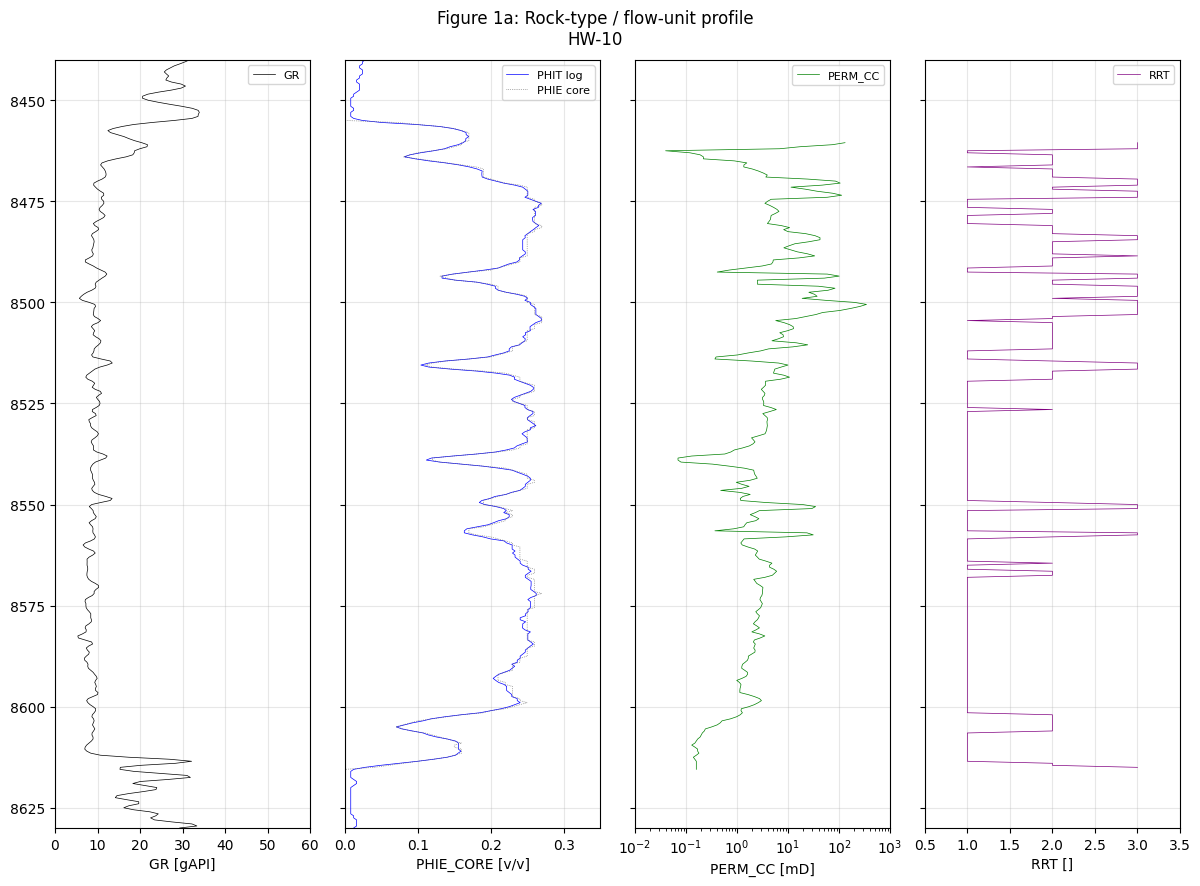

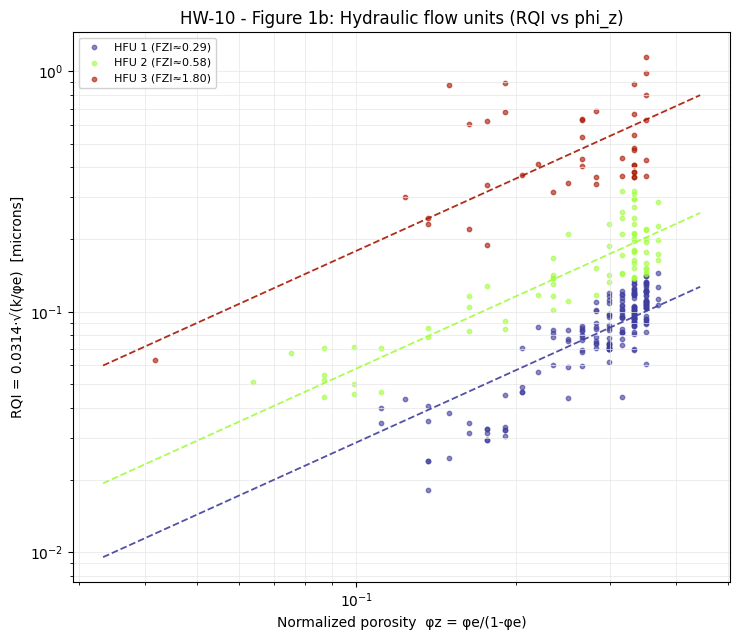

In [14]:
from petrophys.visualization import LogPlot, create_flow_unit_plot

# Attach the depth-mapped rock type so the library log plotter can render it.
well.add_curve('RRT', rrt_full, unit='', description='Reservoir rock type (1=poorest..n=best)')
if not well.has_curve('PHIE_CORE'):
    well.add_curve('PHIE_CORE', phie_cc, unit='v/v', description='Core PHIE_CC')

# Figure 1a: rock-type / flow-unit depth profile via the library LogPlot.
lp = LogPlot(well, figsize=(12, 9))
lp.create_figure(n_tracks=4)
lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
lp.add_curve(1, 'PHIT_LOG', color='blue', xlim=(0, 0.35), label='PHIT log')
lp.add_curve(1, 'PHIE_CORE', color='0.4', linestyle=':', xlim=(0, 0.35), label='PHIE core')
lp.add_curve(2, 'PERM_CC', color='green', log_scale=True, xlim=(0.01, 1000))
lp.add_curve(3, 'RRT', color='purple', xlim=(0.5, fu.n_units + 0.5))
lp.set_depth_range()
lp.add_title('Figure 1a: Rock-type / flow-unit profile')
lp.show()

# Figure 1b: the Amaefule RQI vs phi_z flow-unit diagnostic (the physics behind
# the rock-type partition) rendered by the library flow-unit plotter.
create_flow_unit_plot(result=fu, title='HW-10 - Figure 1b: Hydraulic flow units (RQI vs phi_z)')
plt.show()

### Figure 2 - Poro-perm cloud coloured by rock type, with fitted transforms

The classic diagnostic. A single line (dashed) fits poorly; each rock type follows its own
much tighter trend. Constant-FZI reference lines fan out from the origin.

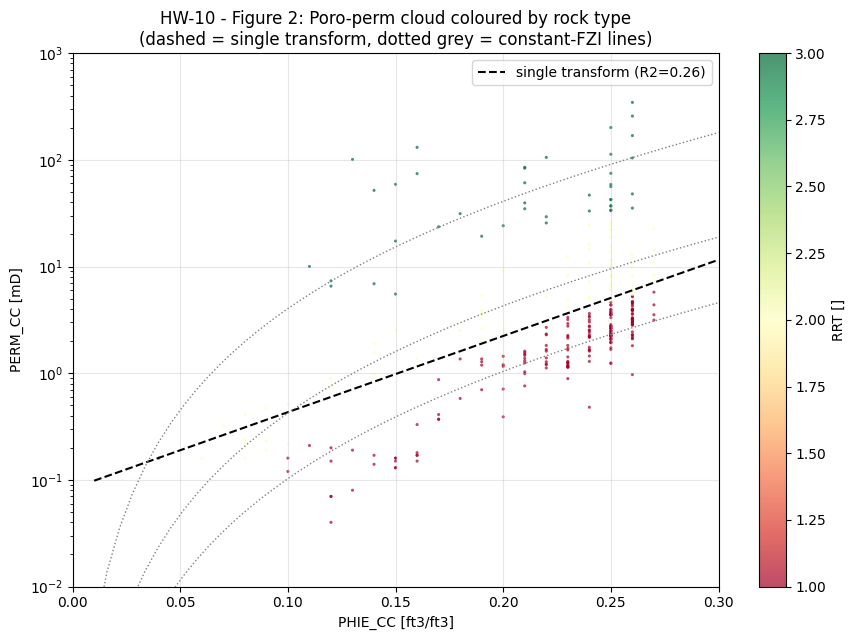

In [15]:
from petrophys.visualization import create_crossplot

# Figure 2: poro-perm cloud coloured by rock type, rendered by the library
# crossplot. RRT and the core curves are already on the well, so the crossplot
# colour-codes each plug by its flow unit directly.
cp = create_crossplot(
    well, 'PHIE_CC', 'PERM_CC', color_curve='RRT',
    y_log=True, xlim=(0, 0.30), ylim=(0.01, 1000), cmap='RdYlGn',
    figsize=(9, 6.5),
    title='HW-10 - Figure 2: Poro-perm cloud coloured by rock type\n'
          '(dashed = single transform, dotted grey = constant-FZI lines)',
)

# Single global transform (dashed) - the poor fit.
cp.add_line(phi_grid, k_single, color='black', linestyle='--', linewidth=1.5,
            label='single transform (R2=%.2f)' % ppt.r_squared)

# Constant-FZI reference lines: K = 1014 * FZI^2 * phi^3/(1-phi)^2
for fzi_ref in fu.fzi_unit_mean:
    k_fzi = 1014.0 * fzi_ref**2 * phi_grid**3 / (1 - phi_grid)**2
    cp.add_line(phi_grid, k_fzi, color='grey', linestyle=':', linewidth=1.0)

cp.show()

### Figure 3 - Core-vs-log calibration crossplots

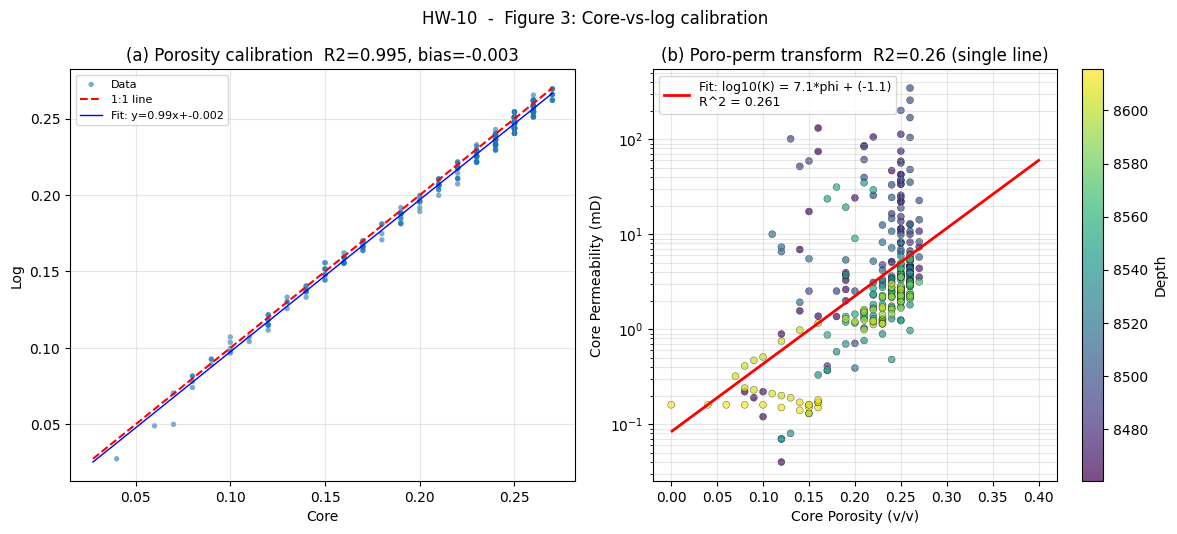

In [16]:
from petrophys.core import plot_calibration, plot_poro_perm

# Figure 3: core-vs-log calibration rendered by the library core plotters.
fig, axs = plt.subplots(1, 2, figsize=(12, 5.4))

# (a) porosity calibration crossplot (log PHIT vs core PHIE) with 1:1 + fit.
plot_calibration(cal, ax=axs[0], title='(a) Porosity calibration  R2=%.3f, bias=%+.3f'
                 % (cal.r_squared, cal.bias))

# (b) poro-perm crossplot with the fitted single transform overlaid (the poor fit
# that motivates rock typing).
plot_poro_perm(core, transform=ppt, ax=axs[1],
               title='(b) Poro-perm transform  R2=%.2f (single line)' % ppt.r_squared)

fig.suptitle('HW-10  -  Figure 3: Core-vs-log calibration', fontsize=12)
plt.tight_layout(); plt.show()

Panel (b) makes the case for rock typing visually: a single poro-perm line scatters
across two orders of magnitude, whereas Figure 2's per-rock-type trends are tight.

### Figure 4 - Saturation-height curve

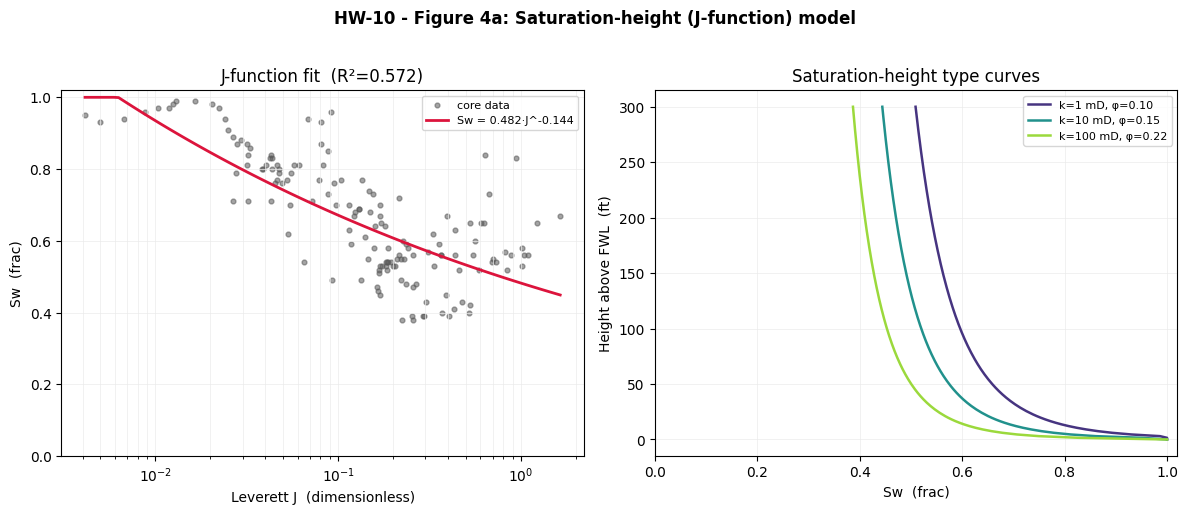

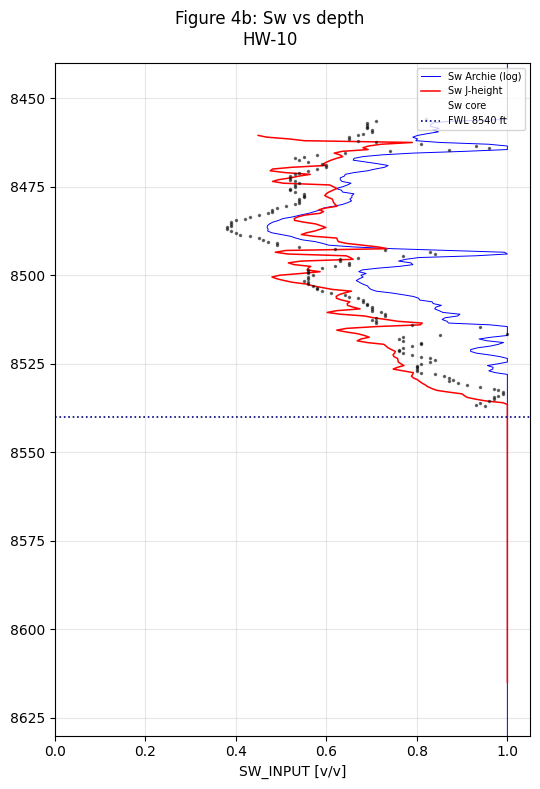

In [17]:
from petrophys.visualization import create_saturation_height_plot, LogPlot

# Figure 4a: the fitted Leverett J-function and the resulting Sw-vs-height type
# curves, rendered by the library saturation-height plotter (left = Sw vs J fit,
# right = Sw-height type curves for a poor/moderate/good rock triplet).
create_saturation_height_plot(
    jmodel, j=Jvals[okJ], sw=sw_c[mJ][okJ],
    title='HW-10 - Figure 4a: Saturation-height (J-function) model',
)
plt.show()

# Figure 4b: Sw vs depth cross-check - Archie log Sw, J-height Sw and core Sw on a
# shared depth track via the library LogPlot (curves already on the well).
lp = LogPlot(well, figsize=(5.5, 8))
lp.create_figure(n_tracks=1)
lp.add_curve(0, 'SW_ARCHIE', color='blue', linewidth=0.7, xlim=(0, 1.05), label='Sw Archie (log)')
lp.add_curve(0, 'SW_JHEIGHT', color='red', linewidth=1.1, xlim=(0, 1.05), label='Sw J-height')
lp.add_curve(0, 'SW_INPUT', color='black', linestyle='', xlim=(0, 1.05), label='Sw core')
lp.axes[0].axhline(FWL, color='navy', ls=':', lw=1.2, label='FWL %.0f ft' % FWL)
lp.axes[0].plot(well.get('SW_INPUT').data, well.depth, 'k.', ms=3, alpha=0.5)
lp.axes[0].legend(loc='upper right', fontsize=7)
lp.set_depth_range()
lp.add_title('Figure 4b: Sw vs depth')
lp.show()

### Figure 5 - Reservoir-quality summary panel

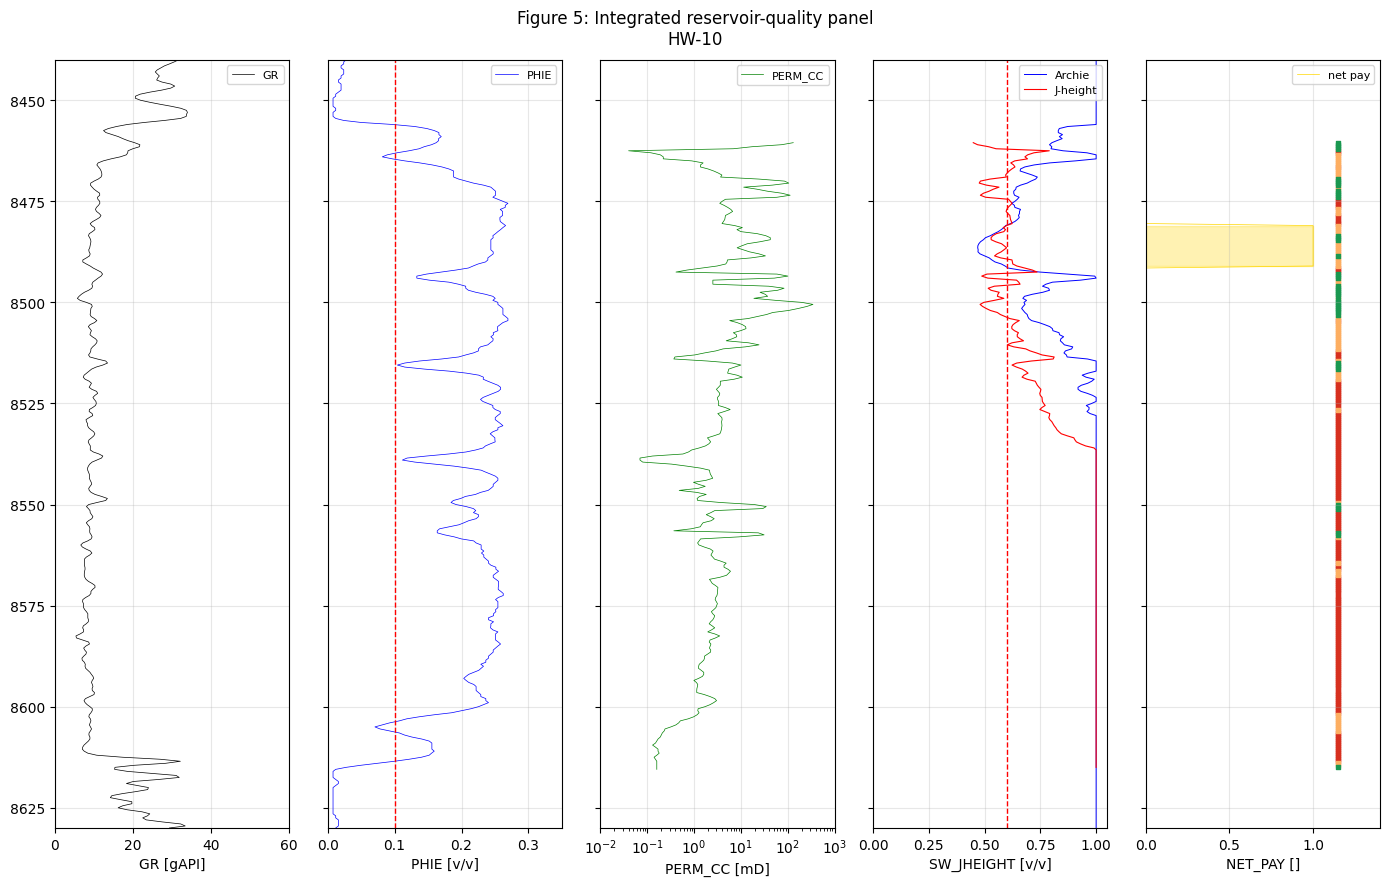

In [18]:
from petrophys.visualization import LogPlot

# Attach the net-pay flag so the library log plotter can shade it as its own track.
well.add_curve('NET_PAY', np.array(npres.net_pay, dtype=float), unit='',
               description='Net-pay flag (carbonate cutoffs)')

# Figure 5: integrated reservoir-quality panel via the library LogPlot.
lp = LogPlot(well, figsize=(14, 9))
lp.create_figure(n_tracks=5)
lp.add_curve(0, 'GR', color='black', xlim=(0, 60))
lp.add_curve(1, 'PHIE', color='blue', xlim=(0, 0.35))
lp.axes[1].axvline(PHIE_CUT, color='r', ls='--', lw=1)
lp.add_curve(2, 'PERM_CC', color='green', log_scale=True, xlim=(0.01, 1000))
lp.add_curve(3, 'SW', color='blue', linewidth=0.7, xlim=(0, 1.05), label='Archie')
lp.add_curve(3, 'SW_JHEIGHT', color='red', linewidth=0.8, xlim=(0, 1.05), label='J-height')
lp.axes[3].axvline(SW_CUT, color='r', ls='--', lw=1)
lp.add_curve(4, 'NET_PAY', color='gold', xlim=(0, 1.4), label='net pay')
lp.add_fill(4, 'NET_PAY', 0.0, color='gold', where='right')
# overlay the rock-type squares alongside the net-pay flag
for rt_id in range(1, fu.n_units + 1):
    sel = rrt_full == rt_id
    lp.axes[4].scatter(np.full(int(sel.sum()), 1.15), well.depth[sel], s=10,
                       c=rt_colors[rt_id - 1], marker='s')
lp.set_depth_range()
lp.add_title('Figure 5: Integrated reservoir-quality panel')
lp.show()

### Figure 6 - Rock-type quality bars (deliverable summary)

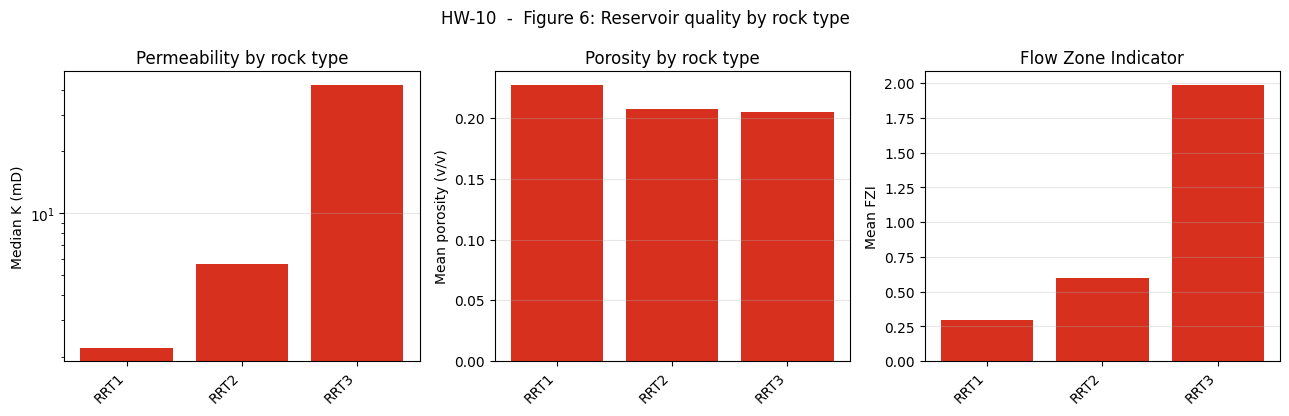

In [19]:
from petrophys.visualization import create_bar_comparison

# Figure 6: reservoir quality by rock type - three grouped bar charts via the
# library bar-comparison helper.
labels = ['RRT%d' % i for i in range(1, fu.n_units + 1)]
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2))

create_bar_comparison(labels, rt_table['K_median_mD'].values, colors=rt_colors,
                      ylabel='Median K (mD)', title='Permeability by rock type', ax=axs[0])
axs[0].set_yscale('log')

create_bar_comparison(labels, rt_table['Phi_mean'].values, colors=rt_colors,
                      ylabel='Mean porosity (v/v)', title='Porosity by rock type', ax=axs[1])

create_bar_comparison(labels, rt_table['FZI_mean'].values, colors=rt_colors,
                      ylabel='Mean FZI', title='Flow Zone Indicator', ax=axs[2])

fig.suptitle('HW-10  -  Figure 6: Reservoir quality by rock type', fontsize=12)
plt.tight_layout(); plt.show()

### Reservoir-quality summary table

In [20]:
summary = rt_table.copy()
summary['Quality'] = ['Poor (tight/micro)', 'Fair', 'Good', 'Excellent'][:fu.n_units]
print('=== HW-10 RESERVOIR-QUALITY SUMMARY ===')
print(summary.to_string(index=False))
print()
print('Field-wide metrics:')
print('  Gross interval  : %.1f ft' % npres.gross_thickness)
print('  Net reservoir   : %.1f ft' % npres.net_reservoir_thickness)
print('  Net pay         : %.1f ft' % npres.net_pay_thickness)
print('  Log porosity vs core R^2 : %.3f (excellent calibration)' % cal.r_squared)
print('  Single poro-perm R^2     : %.2f (poor -> rock typing required)' % ppt.r_squared)

=== HW-10 RESERVOIR-QUALITY SUMMARY ===
RockType  N_plugs  Phi_mean  K_median_mD  K_max_mD  RQI_mean  FZI_mean  Depth_top  Depth_base            Quality
    RRT1      190     0.227         2.20       5.8     0.089     0.293     8462.5      8613.5 Poor (tight/micro)
    RRT2       77     0.207         5.67      25.7     0.159     0.599     8463.5      8614.5               Fair
    RRT3       43     0.205        42.40     345.3     0.494     1.986     8460.5      8615.0               Good

Field-wide metrics:
  Gross interval  : 190.5 ft
  Net reservoir   : 149.5 ft
  Net pay         : 10.5 ft
  Log porosity vs core R^2 : 0.995 (excellent calibration)
  Single poro-perm R^2     : 0.26 (poor -> rock typing required)


## 6. Interpretation & deliverable

**Rock-type profile.** The core resolves into **three hydraulic flow units**:

- **RRT1 (poorest):** the bulk of the plugs; high porosity (~0.23) but low permeability
  (~2 mD median) - classic carbonate **micro-porosity** that stores water but does not flow.
- **RRT2 (fair):** intermediate (~6 mD).
- **RRT3 (best):** the sweet spot - median permeability an order of magnitude higher
  (~40 mD) at similar porosity, indicating better-connected pore geometry (inter-crystalline /
  moldic). RRT3 is the completion target.

**Why porosity alone misled us.** Log porosity calibrates to core almost perfectly
(R^2 ~ 0.99), yet a single poro-perm line explains only ~26% of permeability variance. The
permeability - and hence deliverability - is controlled by *pore geometry*, captured by FZI,
not by porosity. Completing on a porosity cutoff alone would target water-filled micro-porosity.

**Saturation model.** Archie is appropriate (clean carbonate, negligible clay). Once RW is
temperature-corrected from 68 to formation temperature, log Sw tracks core Sw at r ~ 0.97.
The independent J-function saturation-height model corroborates the profile above the FWL.

**Deliverable - reservoir-quality assessment of HW-10:**
- Net reservoir ~150 ft; net pay ~10-30 ft depending on the Sw cutoff (this is a wet-leaning
  interval - core Sw averages ~0.67).
- **Best reservoir = RRT3 intervals** (median K ~40 mD): these high-FZI streaks are the
  primary completion / perforation targets. RRT1 micro-porosity intervals, though high
  porosity, should be excluded.
- Recommendation: perforate the RRT3 flow-unit streaks in the upper part of the reservoir,
  above the ~8540 ft FWL, where Sw is lowest and FZI highest.

## 7. Limitations & assumptions

- **No sonic (DT all-null):** could not cross-check porosity with acoustic; relied on N-D with
  an assumed 2.71 g/cc limestone matrix. Dolomite stringers (matrix ~2.87) would bias porosity.
- **RW temperature correction is decisive:** using surface RW gives Sw>1 everywhere. We used
  the header BHT (251 F) and an Arps correction; an error in BHT propagates directly to Sw.
- **Archie assumption:** justified by low GR, but any conductive minerals or significant
  clay-bound water would require **Waxman-Smits** or **Dual-Water** (both available in
  `petrophysics.saturation`) and would lower the computed Sw.
- **Single poro-perm transform is intentionally poor** and must not be used for prediction;
  use the per-rock-type FZI classes instead.
- **FWL is inferred** from where core Sw -> 1 (~8540 ft), not from pressure (RFT/MDT) data;
  the saturation-height curve inherits that uncertainty.
- **Log Sw over-reads core Sw** slightly (bulk RT vs plug SCAL); net-pay Sw cutoff choice
  therefore carries a few feet of uncertainty.
- Rock-type clustering uses **k-means** with `max_units=4`; the data supported 3 units. A
  different `n_units`/method would shift boundaries.

## 8. Appendix - reproduce on another well

Every Costa well (`petrophys.list_samples('costa')`) carries the same curve set and header
Archie parameters, so this workflow ports directly. The function below runs the core chain on
any Costa well and returns the rock-type table + net pay.

In [21]:
def rock_type_report(well_name, phie_cut=0.10, sw_cut=0.60):
    w = read_las(petrophys.sample(well_name))
    rw  = w.get_parameter('RW');  rwt = w.get_parameter('RWT')
    a   = w.get_parameter('A');   m   = w.get_parameter('M')
    n   = w.get_parameter('N');   bht = w.get_parameter('BHT')

    rhob = w.get('RHOB').data; nphi = w.get('NPHI').data
    phid = poro.density_porosity(rhob, 2.71, 1.0)
    phi  = np.clip(poro.total_porosity(nphi, phid, method='adaptive'), 0, 0.45)

    tp   = calculate_temperature_profile(w, bht=bht, surface_temp=rwt)
    rwfm = arps_equation(rw, rwt, tp.temperature)
    swv  = np.clip(sat.archie(w.get('RT').data, rwfm, phi, a=a, m=m, n=n), 0, 1)

    kc, pc = w.get('PERM_CC').data, w.get('PHIE_CC').data
    ok = np.isfinite(kc) & np.isfinite(pc) & (kc > 0) & (pc > 0)
    f  = res_mod.calculate_flow_units(kc[ok], pc[ok], method='kmeans', max_units=4)

    gr = w.get('GR').data
    w.add_curve('VCL', np.clip((gr-8)/(40-8), 0, 1))
    w.add_curve('PHIE', phi); w.add_curve('SW', swv)
    npr = res_mod.calculate_net_pay(w, vcl_cutoff=0.30, phie_cutoff=phie_cut,
                                    sw_cutoff=sw_cut, lithology='carbonate')
    return {'well': w.name, 'n_flow_units': f.n_units,
            'FZI_means': np.round(f.fzi_unit_mean, 3).tolist(),
            'net_pay_ft': round(npr.net_pay_thickness, 1),
            'net_res_ft': round(npr.net_reservoir_thickness, 1)}

for wn in ['HW-10', 'HW-3', 'HW-24']:
    print(rock_type_report(wn))

{'well': 'HW-10', 'n_flow_units': 3, 'FZI_means': [0.286, 0.581, 1.795], 'net_pay_ft': 10.5, 'net_res_ft': 149.5}
{'well': 'HW-3', 'n_flow_units': 4, 'FZI_means': [0.368, 0.705, 1.911, 10.142], 'net_pay_ft': 168.5, 'net_res_ft': 173.0}
{'well': 'HW-24', 'n_flow_units': 3, 'FZI_means': [0.388, 0.83, 3.657], 'net_pay_ft': 147.0, 'net_res_ft': 167.0}


---
### Recap
- Carbonate reservoir quality is controlled by **pore geometry (FZI)**, not porosity alone.
- **Calibrate to core**: porosity ties tightly; a single poro-perm line does not - use rock
  types.
- **Temperature-correct RW** before Archie or Sw is nonsense.
- The deliverable is a **ranked rock-type profile** identifying **RRT3** as the best flow unit
  and completion target.

### See also
- Tutorials on porosity, saturation, and reservoir quality for the single-module mechanics.
- **CS3** scales this screening across all 17 Costa wells.